# STAT-S 650 Time Series Analysis
# Homework 1

## Manish Suresh Maudgalya
---

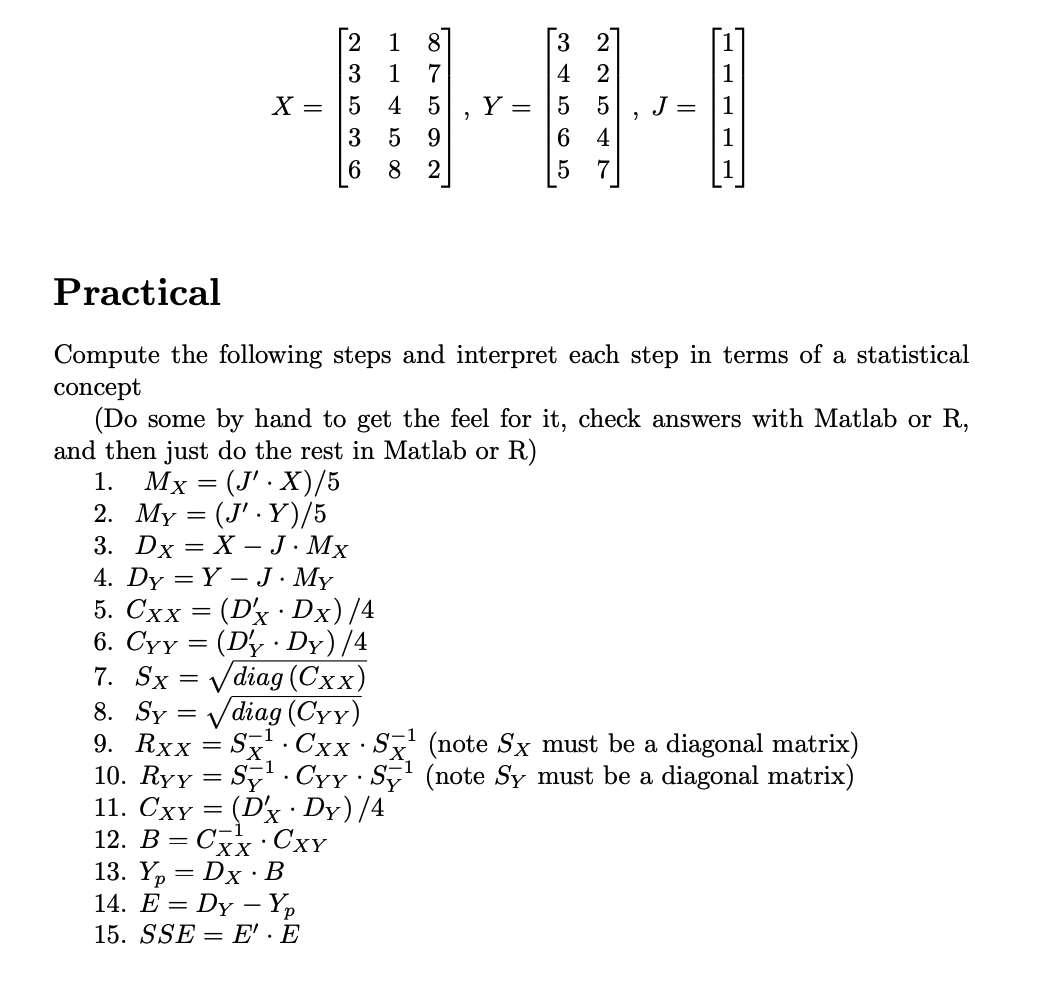

In [3]:
%load_ext rpy2.ipython
#Loading R Cell Magic in a Jupyter Notebook

In [5]:
%%R

# Matrix X
X <- matrix(c(
  2, 1, 8,
  3, 1, 7,
  5, 4, 5,
  3, 5, 9,
  6, 8, 2
), nrow = 5, byrow = TRUE)


# Matrix Y
Y <- matrix(c(
    3,2,
    4,2,
    5,5,
    6,4,
    5,7
), nrow = 5, byrow = TRUE)

# Matrix J
J <- matrix(1, nrow = 5, ncol = 1)


In [7]:
%%R
# 1. Mx = (J' * X)/5
M_X <- (t(J) %*% X) / 5
print(M_X)

     [,1] [,2] [,3]
[1,]  3.8  3.8  6.2


In [8]:
%%R
# 2. My = (J' * Y)/5
M_y <- (t(J) %*% Y)/5
print(M_y)

     [,1] [,2]
[1,]  4.6    4


In [11]:
%%R
# 3. Dx = X-J * Mx
jmx <- (J %*% M_X)
dx <- (X-jmx)
print(dx)

     [,1] [,2] [,3]
[1,] -1.8 -2.8  1.8
[2,] -0.8 -2.8  0.8
[3,]  1.2  0.2 -1.2
[4,] -0.8  1.2  2.8
[5,]  2.2  4.2 -4.2


In [12]:
%%R
# 4. Dy = Y -J * My
jmy <- (J %*% M_y)
dy <- (Y-jmy)
print(dy)

     [,1] [,2]
[1,] -1.6   -2
[2,] -0.6   -2
[3,]  0.4    1
[4,]  1.4    0
[5,]  0.4    3


In [13]:
%%R
# 5. Cxx = (D'x * Dx)/4
cxx <- (t(dx) %*% dx)/4
print(cxx)

      [,1]  [,2]  [,3]
[1,]  2.70  3.95 -4.20
[2,]  3.95  8.70 -5.45
[3,] -4.20 -5.45  7.70


In [14]:
%%R
# 6. Cyy = (D'y * Dy)/4
cyy <-(t(dy) %*% dy)/4
print(cyy)

     [,1] [,2]
[1,]  1.3  1.5
[2,]  1.5  4.5


In [20]:
%%R
# 7. Sx = Root(diag(Cxx))
sx <- sqrt(diag(cxx))
print(sx)

[1] 1.643168 2.949576 2.774887


In [21]:
%%R
# 8. Sy = Root(diag(Cyy))
sy <- sqrt(diag(cyy))
print(sy)

[1] 1.140175 2.121320


In [23]:
%%R
# 9. Rxx = S^-1x * Cxx * S^-1x
sx_inv <- 1/diag(sx)
rxx <- sx_inv %*% cxx %*% sx_inv
print(rxx)

     [,1] [,2] [,3]
[1,]  NaN  NaN  NaN
[2,]  NaN  NaN  NaN
[3,]  NaN  NaN  NaN


In [24]:
%%R
# 10. Ryy = S^-1y * Cyy * S^-1y
sy_inv <- 1/diag(sy)
ryy <- sy_inv %*% cyy %*% sy_inv
print(ryy)

     [,1] [,2]
[1,]  Inf  Inf
[2,]  Inf  Inf


In [25]:
%%R
# 11. Cxy = (D'x * Dy)/4
cxy <- (t(dx) %*% dy)/4
print(cxy)

     [,1]  [,2]
[1,]  0.9  3.25
[2,]  2.4  6.00
[3,] -0.4 -4.75


In [26]:
%%R
# 12. B = C^-1xx * Cxy
cxx_inv <- 1/cxx
b <- cxx_inv %*% cxy
print(b)

           [,1]      [,2]
[1,]  1.0361664  3.853643
[2,]  0.5771047  2.384000
[3,] -0.7066007 -2.491610


In [28]:
%%R
# 13. Yp = Dx * B
yp <- dx %*% b
print(yp)

          [,1]       [,2]
[1,] -4.752874 -18.096655
[2,] -3.010107 -11.751402
[3,]  2.206741   8.091104
[4,] -2.114890  -7.198623
[5,]  7.671129  28.955576


In [29]:
%%R
# 14. E = Dy - Yp
e <- dy - yp
print(e)

          [,1]       [,2]
[1,]  3.152874  16.096655
[2,]  2.410107   9.751402
[3,] -1.806741  -7.091104
[4,]  3.514890   7.198623
[5,] -7.271129 -25.955576


In [31]:
%%R
# 15. SSE = E' * E
sse <- (t(e) %*% e)
print(sse)

         [,1]      [,2]
[1,]  84.2373  301.0931
[2,] 301.0931 1129.9880


In [35]:
%%R
# 16. Eigen values, Eigen Vectors and V * L * V' compared with Cxx
eigen_CXX <- eigen(cxx)

V <- eigen_CXX$vectors
L <- diag(eigen_CXX$values)

vlvt <- V %*% L %*% t(V)

In [36]:
%%R
cat("Eigenvalues (diagonal of L):\n")
print(diag(L))

Eigenvalues (diagonal of L):
[1] 16.1353707  2.7890851  0.1755442


In [37]:
%%R
cat("\nEigenvectors (columns of V):\n")
print(V)


Eigenvectors (columns of V):
           [,1]       [,2]       [,3]
[1,] -0.3937119 -0.1390581  0.9086549
[2,] -0.6702615  0.7199034 -0.1802461
[3,]  0.6290791  0.6800015  0.3766398


In [38]:
%%R
cat("V * L * V\n")
print(vlvt)

V * L * V
      [,1]  [,2]  [,3]
[1,]  2.70  3.95 -4.20
[2,]  3.95  8.70 -5.45
[3,] -4.20 -5.45  7.70


In [40]:
%%R
cat("Cxx from above\n")
print(cxx)

Cxx from above
      [,1]  [,2]  [,3]
[1,]  2.70  3.95 -4.20
[2,]  3.95  8.70 -5.45
[3,] -4.20 -5.45  7.70
